# Spectral Clustering from Random-Forest ProximitiesThis notebook builds a proximity matrix from a random forest, uses an eigengap heuristic to estimate the number of clusters, performs spectral clustering on the proximity graph, and compares clusters to Iris species labels.

In [ ]:
from forestgap import Proximity, embed, get_prototypes, impute, local_feature_importance, outlier_scoresclass _LegacyProximityModel:    def __init__(self, proximity):        self._proximity = proximity    def fit(self, X, y=None, **fit_kwargs):        self._proximity.fit(X, y, **fit_kwargs)        return self    def attach(self, X, y=None):        self._proximity.attach(X, y)        return self    def set_params(self, **params):        prox_params = {}        for key in ("relation", "prox_method", "matrix_type", "non_zero_diagonal", "symm_mode", "max_normalize", "random_state"):            if key in params:                prox_params[key] = params.pop(key)        if params:            self._proximity.estimator.set_params(**params)        if "prox_method" in prox_params and "relation" not in prox_params:            prox_params["relation"] = prox_params.pop("prox_method")        if prox_params:            rel = prox_params.get("relation", self._proximity.relation)            self._proximity._init_sparse_proximity(                prox_method=rel,                matrix_type=prox_params.get("matrix_type", self._proximity.matrix_type),                non_zero_diagonal=prox_params.get("non_zero_diagonal", self._proximity.non_zero_diagonal),                symm_mode=prox_params.get("symm_mode", self._proximity.symm_mode),                max_normalize=prox_params.get("max_normalize", self._proximity.max_normalize),            )            if "random_state" in prox_params:                self._proximity.random_state = prox_params["random_state"]        return self    def get_params(self, deep=True):        params = {}        try:            params.update(self._proximity.estimator.get_params(deep=deep))        except Exception:            pass        params.update({            "relation": self._proximity.relation,            "prox_method": self._proximity.relation,            "matrix_type": self._proximity.matrix_type,            "non_zero_diagonal": self._proximity.non_zero_diagonal,            "symm_mode": self._proximity.symm_mode,            "max_normalize": self._proximity.max_normalize,        })        return params    def phate(self, **kwargs):        return embed(self._proximity, method="phate", **kwargs)    def outlier_scores(self, *args, **kwargs):        return outlier_scores(self._proximity, *args, **kwargs)    def impute(self, *args, **kwargs):        return impute(self._proximity, *args, **kwargs)    def get_prototypes(self, *args, **kwargs):        return get_prototypes(self._proximity, *args, **kwargs)    def local_feature_importance(self, *args, **kwargs):        return local_feature_importance(self._proximity, *args, **kwargs)    def local_variable_importance(self, *args, **kwargs):        return local_feature_importance(self._proximity, *args, **kwargs)    def __getattr__(self, name):        return getattr(self._proximity, name)def compose_proximity(estimator_or_cls):    if isinstance(estimator_or_cls, type):        def _factory(*args, **kwargs):            relation = kwargs.pop("relation", kwargs.pop("prox_method", "rfgap"))            matrix_type = kwargs.pop("matrix_type", "sparse")            non_zero_diagonal = kwargs.pop("non_zero_diagonal", False)            symm_mode = kwargs.pop("symm_mode", None)            max_normalize = kwargs.pop("max_normalize", False)            random_state = kwargs.pop("random_state", None)            estimator = estimator_or_cls(*args, **kwargs)            prox = Proximity(                estimator,                relation=relation,                matrix_type=matrix_type,                non_zero_diagonal=non_zero_diagonal,                symm_mode=symm_mode,                max_normalize=max_normalize,                random_state=random_state,            )            return _LegacyProximityModel(prox)        return _factory    prox = Proximity(estimator_or_cls)    return _LegacyProximityModel(prox)

In [3]:
import sysfrom pathlib import Pathimport matplotlib.pyplot as pltimport numpy as npimport pandas as pdfrom scipy.linalg import eigvalshfrom sklearn.cluster import SpectralClusteringfrom sklearn.ensemble import RandomForestClassifierfrom sklearn.manifold import SpectralEmbeddingfrom sklearn.metrics import adjusted_rand_score, confusion_matrix, normalized_mutual_info_scorefrom sklearn.preprocessing import LabelEncodercwd = Path.cwd().resolve()repo_root = cwd.parent if cwd.name == "notebooks" else cwdif str(repo_root) not in sys.path:    sys.path.insert(0, str(repo_root))from forestgap.datasets import load_openml_datasetRANDOM_STATE = 42MAX_EIGENGAP_K = 10

In [4]:
iris = load_openml_dataset(name="iris", as_frame=True)X_df = iris.X if isinstance(iris.X, pd.DataFrame) else pd.DataFrame(iris.X, columns=iris.feature_names)y_raw = iris.yif isinstance(y_raw, pd.DataFrame):    y_raw = y_raw.iloc[:, 0]if isinstance(y_raw, pd.Series):    y_text = y_raw.to_numpy()else:    y_text = np.asarray(y_raw)y = LabelEncoder().fit_transform(y_text)X = X_df.to_numpy(dtype=float)print(f"Loaded {X.shape[0]} samples with {X.shape[1]} features from OpenML dataset id {iris.dataset_id}.")print(f"Class labels: {np.unique(y_text)}")

Loaded 150 samples with 4 features from OpenML dataset id 42871.
Class labels: ['1' '2' '3']


In [ ]:
ProxRF = compose_proximity(RandomForestClassifier)rf = ProxRF(    n_estimators=400,    random_state=RANDOM_STATE,    n_jobs=-1,    bootstrap=True,    prox_method="oob",    matrix_type="dense",)rf.fit(X, y)P = np.asarray(rf.get_proximities(), dtype=float)P = np.clip((P + P.T) / 2.0, 0.0, None)np.fill_diagonal(P, 1.0)print(f"Proximity matrix shape: {P.shape}")print(f"Proximity range: [{P.min():.4f}, {P.max():.4f}]")

Proximity matrix shape: (150, 150)
Proximity range: [0.0000, 1.0000]


Estimated number of clusters from eigengap: k = 5


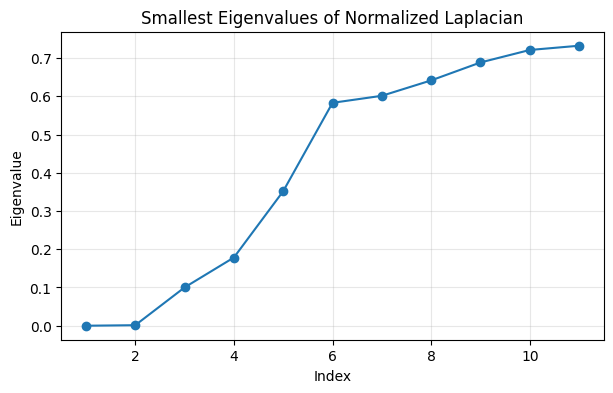

In [6]:
degrees = P.sum(axis=1)inv_sqrt_deg = 1.0 / np.sqrt(np.maximum(degrees, 1e-12))L_sym = np.eye(P.shape[0]) - (inv_sqrt_deg[:, None] * P * inv_sqrt_deg[None, :])n_eval = min(MAX_EIGENGAP_K + 1, P.shape[0] - 1)eigvals = eigvalsh(L_sym)[:n_eval]eig_gaps = np.diff(eigvals)k_est = int(np.argmax(eig_gaps) + 1)print(f"Estimated number of clusters from eigengap: k = {k_est}")plt.figure(figsize=(7, 4))plt.plot(np.arange(1, len(eigvals) + 1), eigvals, marker="o")plt.xlabel("Index")plt.ylabel("Eigenvalue")plt.title("Smallest Eigenvalues of Normalized Laplacian")plt.grid(alpha=0.3)plt.show()

In [10]:
# MANUAL ENTRYk_est = 3

In [11]:
spectral = SpectralClustering(    n_clusters=k_est,    affinity="precomputed",    assign_labels="kmeans",    random_state=RANDOM_STATE,    n_init=20,)cluster_labels = spectral.fit_predict(P)ari = adjusted_rand_score(y, cluster_labels)nmi = normalized_mutual_info_score(y, cluster_labels)cm = confusion_matrix(y, cluster_labels)print(f"ARI: {ari:.4f}")print(f"NMI: {nmi:.4f}")print("Confusion matrix (rows=true class, cols=cluster):")print(cm)

ARI: 0.5869
NMI: 0.6577
Confusion matrix (rows=true class, cols=cluster):
[[ 0  0 50]
 [24 25  0]
 [ 5 46  0]]


c:\Users\rhodes8\AppData\Local\miniconda3\envs\treeple\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


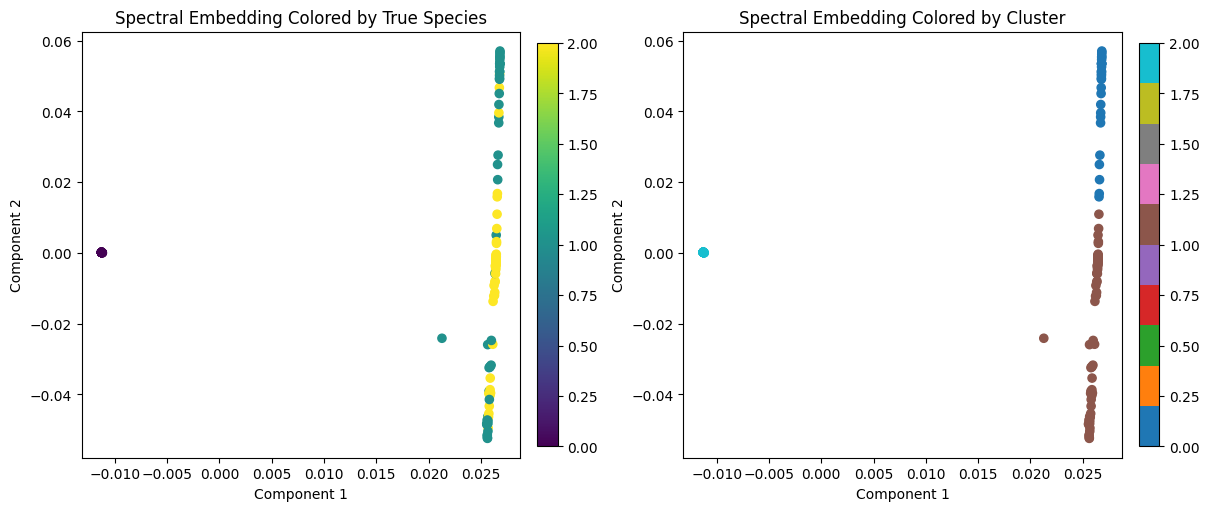

In [12]:
embedding = SpectralEmbedding(n_components=2, affinity="precomputed", random_state=RANDOM_STATE)Z = embedding.fit_transform(P)fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)scatter0 = axes[0].scatter(Z[:, 0], Z[:, 1], c=y, cmap="viridis", s=35)axes[0].set_title("Spectral Embedding Colored by True Species")axes[0].set_xlabel("Component 1")axes[0].set_ylabel("Component 2")fig.colorbar(scatter0, ax=axes[0], fraction=0.046, pad=0.04)scatter1 = axes[1].scatter(Z[:, 0], Z[:, 1], c=cluster_labels, cmap="tab10", s=35)axes[1].set_title("Spectral Embedding Colored by Cluster")axes[1].set_xlabel("Component 1")axes[1].set_ylabel("Component 2")fig.colorbar(scatter1, ax=axes[1], fraction=0.046, pad=0.04)plt.show()

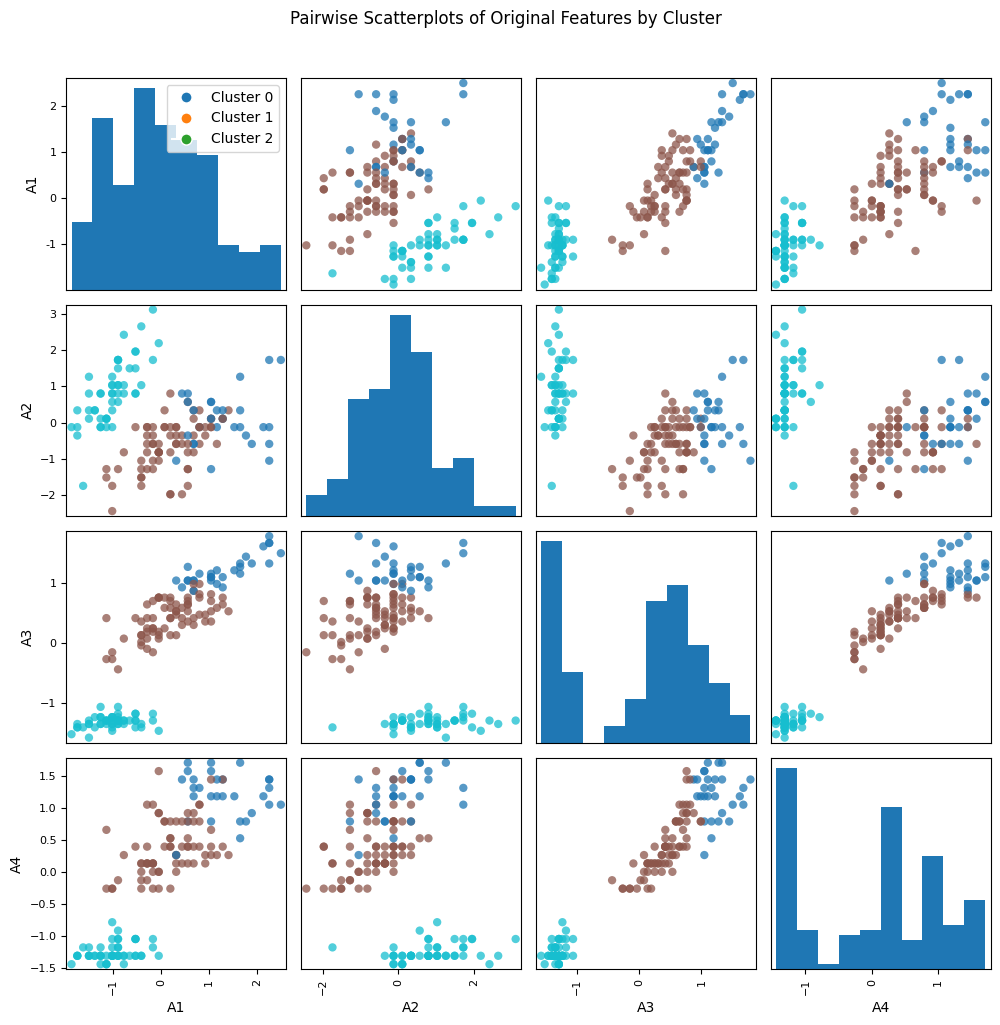

In [13]:
from matplotlib.lines import Line2Dfeature_df = X_df.copy()feature_names = feature_df.columns.tolist()axes = pd.plotting.scatter_matrix(    feature_df[feature_names],    c=cluster_labels,    cmap="tab10",    figsize=(10, 10),    diagonal="hist",    alpha=0.75,    marker="o",)cluster_ids = np.unique(cluster_labels)legend_handles = [    Line2D(        [0],        [0],        marker="o",        color="w",        label=f"Cluster {cid}",        markerfacecolor=plt.cm.tab10(int(cid) % 10),        markersize=8,    )    for cid in cluster_ids]axes[0, 0].legend(handles=legend_handles, loc="upper right", frameon=True)plt.suptitle("Pairwise Scatterplots of Original Features by Cluster", y=1.02)plt.tight_layout()plt.show()

## Notes- Proximities are used directly as the affinity matrix for spectral clustering.- The eigengap estimate can be sensitive; if needed, compare with a manually chosen `k`.- You can switch `prox_method` to `"rfgap"` or `"oob"` to compare affinity quality.